# 13C 通量拟合测试

In [1]:
import sys
sys.path.append(r'./ETGEM/etgems_web/')
import ETGEM.etgems_web.script
from ETGEM.etgems_web.script.io.json import *
from ETGEM.etgems_web.script.tcmodel.construct import get_K_value
from ETGEM.etgems_web.script.plotting.plotting import *
import numpy as np
from ETGEM.etgems_web.script.analysis.flux_balance_analysis import *
from ETGEM.etgems_web.script.analysis.max_driving_force import *
from ETGEM.etgems_web.script.ecmpy.ECMpy_function import *


# etiZM564

In [2]:
model_path = "./model/ETiZM564_MM_optimized.json"
model = read_json_model(model_path)
model.obj_name = "ZM_BIOMASS"
model.medium['EX_glc_D_e_reverse'] = 1000
model.get_reaction_by_id("EX_glc_D_e_reverse").bounds = (0, 1000)
opt_etm = calculate_ETM(model, "maximize", 0.0)
print(opt_etm.obj())
for i in model.reactions:
    if opt_etm.reaction[i].value > 1e-4:
        percent = opt_etm.reaction[i].value/opt_etm.reaction["EX_glc_D_e_reverse"].value*100
        print(f"{i}\t{model.reactions[i].build_reaction_string(model,use_metabolite_names=True)}\t{model.reactions[i].bounds}\t{opt_etm.reaction[i].value:.3f}\t{percent:.3f}%")



0.36077388684111794
ACTNtex	(S)-Acetoin <=> (S)-Acetoin	(0.0, 1000.0)	0.725	1.358%
ACTNtpp	(S)-Acetoin <=> (S)-Acetoin	(0.0, 1000.0)	0.725	1.358%
ATPM	H2O + ATP <=> ADP + Phosphate + H+	(3.71, 3.71)	3.710	6.952%
EX_ac_e	Acetate <=> 	(0.0, 1000.0)	0.053	0.098%
EX_actn__S_e	(S)-Acetoin <=> 	(0.0, 1000.0)	0.725	1.358%
EX_co2_e	CO2 <=> 	(0.0, 1000.0)	101.250	189.731%
EX_etoh_e	Ethanol <=> 	(0.0, 1000.0)	100.080	187.540%
EX_h2o_e	H2O <=> 	(0.0, 1000.0)	18.541	34.744%
EX_succ_e	Succinate <=> 	(0.0, 1000.0)	0.227	0.426%
HPN	H2O + Bacteriohopanetetrol-acetylglucosamine <=> Acetate + H+ + Tetrahydroxybacteriohopane-glucosamine	(0.0, 1000.0)	0.013	0.024%
HPN4	UDP-glucosamine + Tetrahydroxybacteriohopane <=> UDP + H+ + Bacteriohopanetetrol-acetylglucosamine	(0.0, 1000.0)	0.013	0.024%
rxn00085	NADP + L-Glutamate <=> NADPH + 2-Oxoglutarate + L-Glutamine + H+	(-1000.0, 0.0)	3.284	6.154%
rxn00086	NADP + GSH <=> NADPH + H+ + Oxidized glutathione	(-1000.0, 0.0)	0.045	0.085%
rxn00119	ATP + H+ + UMP <=> 

In [3]:
model_path = "./model/ETiZM564_MM_optimized_23BDO.json"
model = read_json_model(model_path)
model.obj_name = "ZM_BIOMASS"
for rxn in model.reactions:
    if "ZMO1360" in model.get_reaction_by_id(rxn).gene_reaction_rule:
        model.get_reaction_by_id(rxn).bounds = (0,0)
model.add_medium("EX_glc_D_e_reverse",100)
model.get_reaction_by_id('EX_glc_D_e').bounds = (0,0)

for o2rxn in ["rxn00262",'rxn00208']:
    model.get_reaction_by_id(o2rxn).bounds = (0,0)
o2_level = 6
model.add_medium("EX_o2_e_reverse",o2_level)
model.get_reaction_by_id("EX_o2_e_reverse").bounds = (0,o2_level)
max_bdo = 22.912    # 无氧条件下最大生产速率
beta = 1
# 调用calculate_ETM
alpha = max_bdo*1.3 - o2_level * beta
def make_rule(a,m):
    def rule(m):
        return m.reaction['rxn02112_reverse'] <= a
    return rule
custom_constraints = {
    '23BDO_limit': make_rule(alpha,model)
}
opt_etm = calculate_ETM(model, "maximize", 0, custom_constraints=custom_constraints)
print(opt_etm.obj())
for i in model.reactions:
    if opt_etm.reaction[i].value > 1e-4:
        percent = opt_etm.reaction[i].value/opt_etm.reaction["EX_glc_D_e_reverse"].value*100
        print(f"{i}\t{model.reactions[i].build_reaction_string(model,use_metabolite_names=True)}\t{model.reactions[i].bounds}\t{opt_etm.reaction[i].value:.3f}\t{percent:.3f}%")



0.05811853822859111
ATPM	H2O + ATP <=> ADP + Phosphate + H+	(3.71, 3.71)	3.710	15.297%
EX_ac_e	Acetate <=> 	(0.0, 1000.0)	0.032	0.132%
EX_co2_e	CO2 <=> 	(0.0, 1000.0)	47.455	195.663%
EX_duri_e	Deoxyuridine <=> 	(0.0, 1000.0)	0.026	0.106%
EX_etoh_e	Ethanol <=> 	(0.0, 1000.0)	0.074	0.306%
EX_for_e	Formate <=> 	(0.0, 1000.0)	0.169	0.697%
EX_glyc_e	Glycerol <=> 	(0.0, 1000.0)	0.000	0.001%
GLYCtpp	Glycerol <=> Glycerol	(0.0, 1000.0)	1000.000	4123.114%
EX_h_e	H+ <=> 	(0.0, 1000.0)	1000.000	4123.116%
EX_h2o_e	H2O <=> 	(0.0, 1000.0)	12.991	53.563%
EX_h2s_e	H2S <=> 	(0.0, 1000.0)	2.476	10.207%
EX_mg2_e	Mg <=> 	(0.0, 1000.0)	1000.000	4123.115%
EX_succ_e	Succinate <=> 	(0.0, 1000.0)	0.036	0.150%
HPN	H2O + Bacteriohopanetetrol-acetylglucosamine <=> Acetate + H+ + Tetrahydroxybacteriohopane-glucosamine	(0.0, 1000.0)	0.002	0.008%
HPN4	UDP-glucosamine + Tetrahydroxybacteriohopane <=> UDP + H+ + Bacteriohopanetetrol-acetylglucosamine	(0.0, 1000.0)	0.002	0.008%
rxn00085	NADP + L-Glutamate <=> NADPH + 2

# eciZM547

In [4]:
ecmodel_path = "eciZM547.json"
model = get_enzyme_constraint_model(ecmodel_path)
model.obj_name = "ZM_BIOMASS"
model.medium['EX_glc_D_e_reverse'] = 1000
model.reactions.get_by_id("EX_glc_D_e_reverse").bounds = (0, 1000)
enz_model_pfba_solution = cobra.flux_analysis.pfba(model)
for i in model.reactions:
    if enz_model_pfba_solution.fluxes[i.id] > 1e-4:
        percent = enz_model_pfba_solution.fluxes[i.id]/enz_model_pfba_solution.fluxes["EX_glc_D_e_reverse"]*100
        print(f"{i.id}\t{model.reactions.get_by_id(i.id).build_reaction_string(use_metabolite_names=True)}\t{enz_model_pfba_solution.fluxes[i.id]:.3f}\t{percent:.3f}%") 


Set parameter LicenseID to value 2845745
rxn00085_reverse	nadph_c + akg_c + gln-L_c + h_c --> nadp_c + 2.0 glu-L_c	4.248	6.204%
rxn00097_num1	atp_c + amp_c + h_c --> 2.0 adp_c	0.980	1.432%
rxn00119	atp_c + h_c + ump_c --> adp_c + UDP_c	0.327	0.478%
rxn00126	h2o_c + atp_c + met-L_c --> pi_c + ppi_c + amet_c + h_c	0.025	0.037%
rxn00134	atp_c + adn_c --> adp_c + amp_c + h_c	0.005	0.008%
rxn00137	h2o_c + pap_c --> pi_c + amp_c	0.053	0.077%
rxn00139_reverse	prpp_c + ade_c --> ppi_c + amp_c + h_c	0.018	0.027%
rxn00148_reverse	adp_c + pep_c + h_c --> atp_c + pyr_c	64.769	94.598%
rxn00168	pyr_c + h_c --> co2_c + acald_c	129.766	189.531%
rxn00179	atp_c + glu-L_c --> adp_c + glu5p_c	0.115	0.167%
rxn00187	atp_c + nh4_c + glu-L_c --> adp_c + pi_c + gln-L_c + h_c	5.256	7.677%
rxn00193_num1	glu-L_c --> glu-D_c	0.006	0.009%
rxn00213	utp_c + g1p_c --> ppi_c + udpg_c	0.013	0.019%
rxn00214	udpg_c --> udpgal_c	0.013	0.019%
rxn00216	atp_c + glc-D_c --> adp_c + h_c + g6p_c	68.467	100.000%
rxn00237	atp_c + 

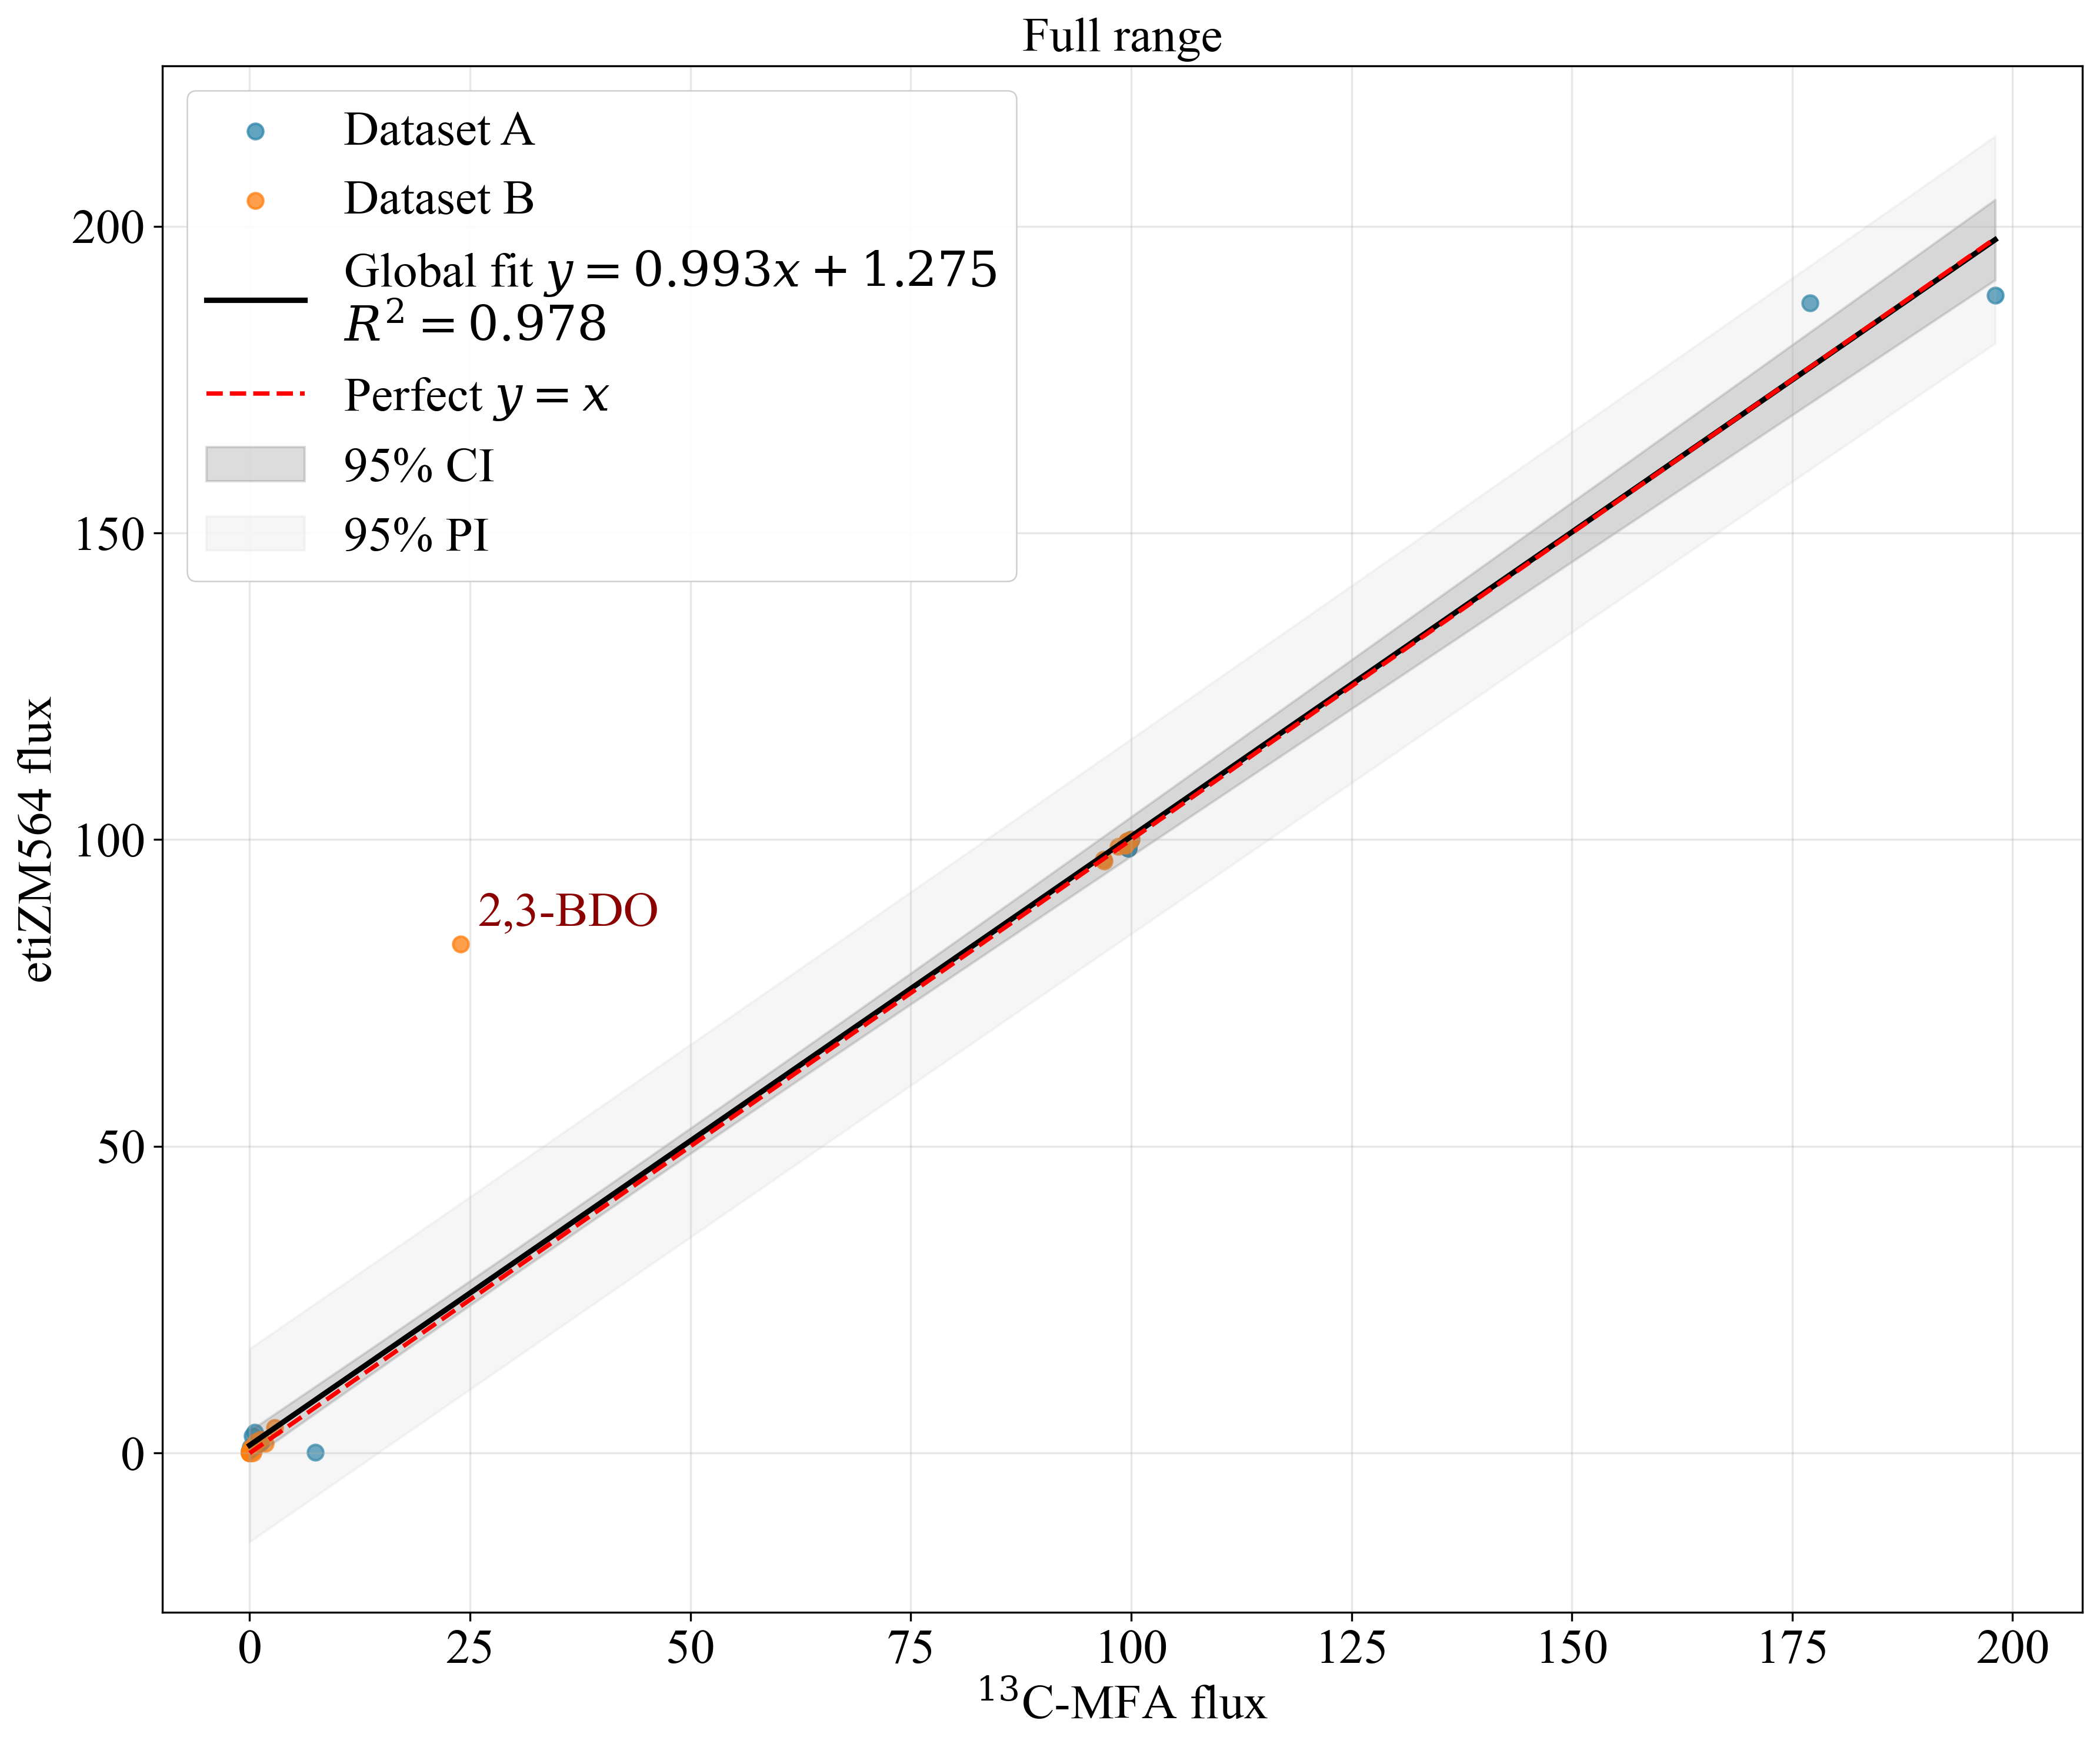

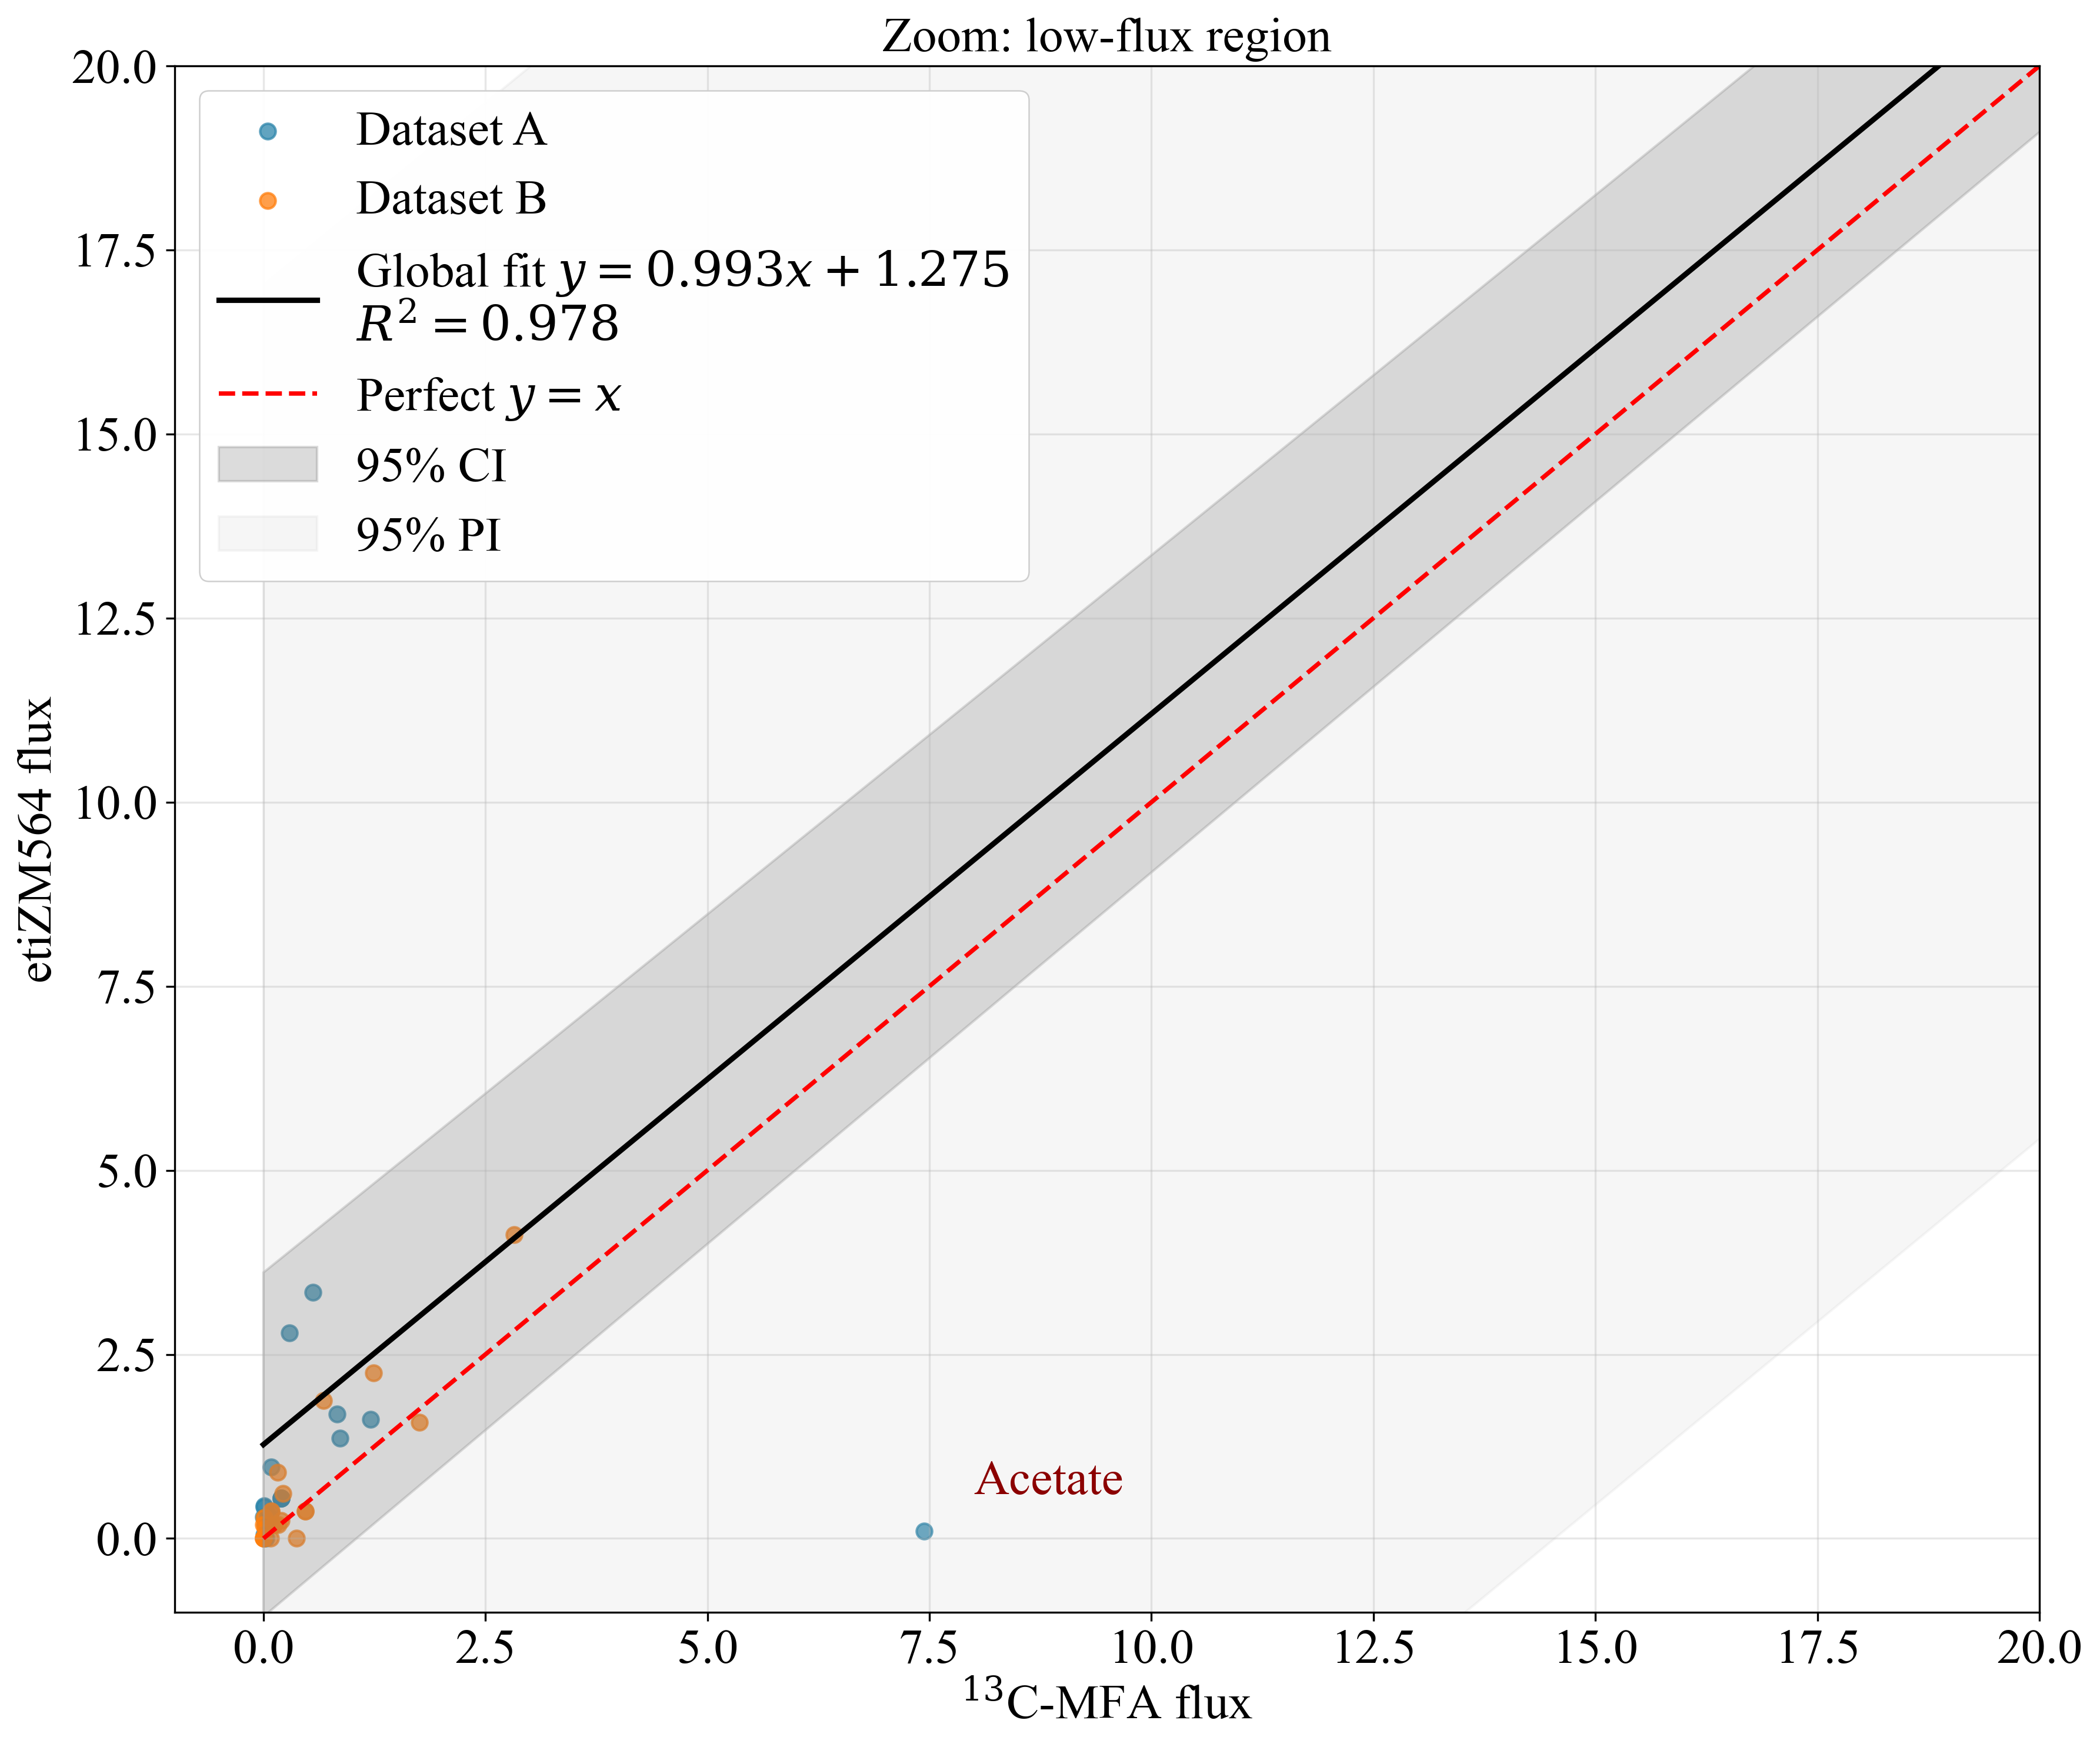

====全局统计结果（报告直接复制）====
n=63
slope=0.9925, 95%CI:[0.9546, 1.0305]
intercept=1.2753
R²=0.9782, p=2.25e-52, RMSE=7.7863
Residual 95% quantile interval: [-4.755, 5.600]
Outlier point 2,3‑BDO residual: 58.02


In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# 全局字体设置 Times New Roman
plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams['mathtext.fontset'] = 'dejavuserif'
plt.rcParams['savefig.dpi'] = 300
plt.rcParams['pdf.fonttype'] = 42   # PDF输出文字矢量

data_A = [
[100, 100],[99.82, 99.60],[99.82, 99.60],[99.82, 99.60],
[0.08, 0.36],[0.003, 0.29],[0.01, 0],[99.70, 98.65],
[99.70, 98.65],[99.70, 98.65],[99.70, 98.65],[198.01, 188.74],
[0.56, 3.34],[7.44, 0.10],[176.99, 187.54],[0.86, 1.36],
[0.83, 1.69],[0.09, 0.97],[0.20, 0.55],[0.03, 0],
[0.29, 2.79],[0.01, 0.43],[0.024, 0.19],[0.20, 0.55],
[0.20, 0.55],[0.20, 0.55],[1.21, 1.62],[0.01, 0.05],
[0.01, 0.44],[0.07, 0.29],[0.05, 0.29]
]

data_B = [
[100, 100],[99.76, 99.73],[99.51, 99.73],[99.51, 99.73],
[0.20, 0.24],[0.003, 0.19],[0.37, 0],[99.35, 99.10],
[99.35, 99.10],[98.52, 98.88],[96.91, 96.50],[1.24, 2.25],
[96.84, 96.82],[23.9, 83.02],[0, 0],[0, 0],
[0, 0],[1.76, 1.58],[0.22, 0.61],[0.47, 0.37],
[0.08, 0],[0.68, 1.87],[0.01, 0.28],[0.02, 0.13],
[0.09, 0.37],[0.09, 0.37],[0.47, 0.37],[2.82, 4.13],
[0.16, 0.90],[0.17, 0.19],[0.12, 0.19],[0.12, 0.19]
]

dfA = pd.DataFrame(data_A, columns=["x_13C","y_model"])
dfB = pd.DataFrame(data_B, columns=["x_13C","y_model"])
dfA["source"]="A"
dfB["source"]="B"
df_all = pd.concat([dfA,dfB],ignore_index=True)

# ========= 全局只做一次回归 =========
x = df_all["x_13C"].values
y = df_all["y_model"].values
slope, intercept, r_value, p_value, std_err = stats.linregress(x,y)
n = len(x)
dof = n-2
t95 = stats.t.ppf(0.975, dof)

x_pred = np.linspace(np.min(x), np.max(x), 300)
y_hat = intercept + slope * x_pred

x_mean = np.mean(x)
Sxx = np.sum((x-x_mean)**2)
residuals = y - (intercept+slope*x)
MSE = np.sum(residuals**2)/dof
s = np.sqrt(MSE)

ci = t95 * s * np.sqrt(1/n + (x_pred-x_mean)**2/Sxx)
pi = t95 * s * np.sqrt(1 + 1/n + (x_pred-x_mean)**2/Sxx)

grpA = df_all[df_all["source"]=="A"]
grpB = df_all[df_all["source"]=="B"]

# ----------------------图1：完整全范围视图（独立画布）----------------------
fig1, ax1 = plt.subplots(figsize=(12,10), dpi=300)
ax1.scatter(grpA["x_13C"],grpA["y_model"],c="#2E86AB",alpha=0.75,s=40,label="Dataset A")
ax1.scatter(grpB["x_13C"],grpB["y_model"],c="#ff7f0e",alpha=0.75,s=40,label="Dataset B")
ax1.plot(x_pred,y_hat,"k-",lw=2.2,label=f"Global fit $y={slope:.3f}x{intercept:+.3f}$\n$R^2={r_value**2:.3f}$")
ax1.plot(x_pred,x_pred,"r--",lw=1.8,label="Perfect $y=x$")
ax1.fill_between(x_pred,y_hat-ci,y_hat+ci,color="#606060",alpha=0.22,label="95% CI")
ax1.fill_between(x_pred,y_hat-pi,y_hat+pi,color="#B8B8B8",alpha=0.12,label="95% PI")

ax1.text(23.9+2, 83.02+3, "2,3‑BDO", fontsize=20, color="darkred")
ax1.set_xlabel(r"$^{13}$C‑MFA flux", fontsize=20)
ax1.set_ylabel(r"etiZM564 flux", fontsize=20)
ax1.set_title("Full range", fontsize=20)
ax1.tick_params(axis='both', labelsize=20)
ax1.grid(alpha=0.3)
leg1 = ax1.legend(fontsize=20, framealpha=0.95)
leg1.get_frame().set_linewidth(0.6)

plt.tight_layout()
plt.savefig("flux_full_TNR.png", bbox_inches="tight", dpi=300)
# plt.savefig("flux_full_TNR.pdf", bbox_inches="tight")
plt.show()
plt.close(fig1)


# ----------------------图2：小通量放大视图（独立画布）----------------------
fig2, ax2 = plt.subplots(figsize=(12,10), dpi=300)
ax2.text(7+1, 0.1+0.5, "Acetate", fontsize=20, color="darkred")
ax2.scatter(grpA["x_13C"],grpA["y_model"],c="#2E86AB",alpha=0.75,s=40,label="Dataset A")
ax2.scatter(grpB["x_13C"],grpB["y_model"],c="#ff7f0e",alpha=0.75,s=40,label="Dataset B")
ax2.plot(x_pred,y_hat,"k-",lw=2.2,label=f"Global fit $y={slope:.3f}x{intercept:+.3f}$\n$R^2={r_value**2:.3f}$")
ax2.plot(x_pred,x_pred,"r--",lw=1.8,label="Perfect $y=x$")
ax2.fill_between(x_pred,y_hat-ci,y_hat+ci,color="#606060",alpha=0.22,label="95% CI")
ax2.fill_between(x_pred,y_hat-pi,y_hat+pi,color="#B8B8B8",alpha=0.12,label="95% PI")

ax2.set_xlim(-1,20)
ax2.set_ylim(-1,20)
ax2.set_xlabel(r"$^{13}$C‑MFA flux", fontsize=20)
ax2.set_ylabel(r"etiZM564 flux", fontsize=20)
ax2.set_title("Zoom: low‑flux region", fontsize=20)
ax2.tick_params(axis='both', labelsize=20)
ax2.grid(alpha=0.3)
leg2 = ax2.legend(fontsize=20, framealpha=0.95)
leg2.get_frame().set_linewidth(0.6)

plt.tight_layout()
plt.savefig("flux_low_zoom_TNR.png", bbox_inches="tight", dpi=300)
# plt.savefig("flux_low_zoom_TNR.pdf", bbox_inches="tight")
plt.show()
plt.close(fig2)


print("====全局统计结果（报告直接复制）====")
print(f"n={n}")
print(f"slope={slope:.4f}, 95%CI:[{slope-t95*std_err:.4f}, {slope+t95*std_err:.4f}]")
print(f"intercept={intercept:.4f}")
print(f"R²={r_value**2:.4f}, p={p_value:.2e}, RMSE={s:.4f}")
print(f"Residual 95% quantile interval: [{np.quantile(residuals,0.025):.3f}, {np.quantile(residuals,0.975):.3f}]")
print(f"Outlier point 2,3‑BDO residual: {83.02-(intercept+slope*23.9):.2f}")
